<a href="https://colab.research.google.com/github/12tangent/Supervised_Learning_Tanay_Choudhari_2026_710/blob/main/Linear_Regression_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression — Complete Teaching & Interpretation Notebook
**PGDM / postgraduate level | Theory, Python implementation, statistical interpretation, diagnostics and practice**

This notebook explains simple and multiple linear regression from the equation to interpretation of model outputs. It covers coefficients, intercept, standard errors, t-tests, p-values, confidence intervals, F-test, R², adjusted R², prediction metrics, residuals, assumptions, VIF, heteroskedasticity, autocorrelation, outliers, leverage, Cook's distance, categorical variables, interactions, transformations, standardised coefficients, cross-validation and regularisation.

**Important:** Regression association is not automatically causation. Interpret results in context and state units.

## 1. Concept and equations

Simple linear regression:

\[
\hat{Y}=b_0+b_1X
\]

Multiple linear regression:

\[
\hat{Y}=b_0+b_1X_1+b_2X_2+\cdots+b_kX_k
\]

- **Y / target / dependent variable:** outcome to explain or predict.
- **X / predictor / independent variable:** input used to explain or predict Y.
- **Intercept (b₀):** predicted Y when all X values are zero.
- **Slope/coefficient (bⱼ):** expected change in predicted Y for a one-unit increase in Xⱼ, **holding other predictors constant**.
- **Residual:** actual value minus predicted value.
- **Least squares:** estimates coefficients by minimising the sum of squared residuals.

A coefficient is expressed in target units per predictor unit. Always state both units.

## 2. Import libraries and create a reproducible dataset

We predict students' final scores using weekly study hours, attendance percentage, previous score and assignment completion percentage. The dataset is synthetic for teaching.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

rng = np.random.default_rng(42)
n = 160
df = pd.DataFrame({
    "study_hours": rng.uniform(1, 15, n),
    "attendance": rng.uniform(55, 100, n),
    "previous_score": rng.uniform(30, 90, n),
    "assignments": rng.uniform(40, 100, n)
})
noise = rng.normal(0, 5, n)
df["final_score"] = np.clip(
    8 + 2.6*df.study_hours + .18*df.attendance
    + .38*df.previous_score + .12*df.assignments + noise,
    0, 100
)
df.head()

,study_hours,attendance,previous_score,assignments,final_score
0,11.835,59.848,84.981,64.527,83.168
1,7.144,96.221,58.855,53.058,76.196
2,13.020,65.360,49.702,75.298,82.748
3,10.763,56.684,62.126,59.022,73.808
4,2.318,79.968,80.914,42.164,71.485


## 3. Data understanding and exploratory analysis

Inspect shape, types, missing values, descriptive statistics, distributions, outliers and relationships before fitting a model. A scatterplot can reveal curvature; a histogram can reveal skewness; correlation describes pairwise linear association, not causation.

In [2]:
print("Shape:", df.shape)


Shape: (160, 5)


In [3]:
display(df.dtypes.to_frame("Data type"))


,Data type
study_hours,float64
attendance,float64
previous_score,float64
assignments,float64
final_score,float64


In [4]:
display(df.isna().sum().to_frame("Missing values"))


,Missing values
study_hours,0
attendance,0
previous_score,0
assignments,0
final_score,0


In [5]:
display(df.describe().T)



,count,mean,std,min,25%,50%,75%,max
study_hours,160.000,7.860,3.838,1.103,4.734,7.706,11.045,14.659
attendance,160.000,76.603,13.456,55.627,64.998,75.626,90.001,99.657
previous_score,160.000,61.207,17.837,30.326,44.416,64.513,76.659,89.946
assignments,160.000,71.145,17.155,40.439,58.606,71.361,85.860,99.728
final_score,160.000,73.741,14.015,36.345,65.069,74.738,84.895,100.000


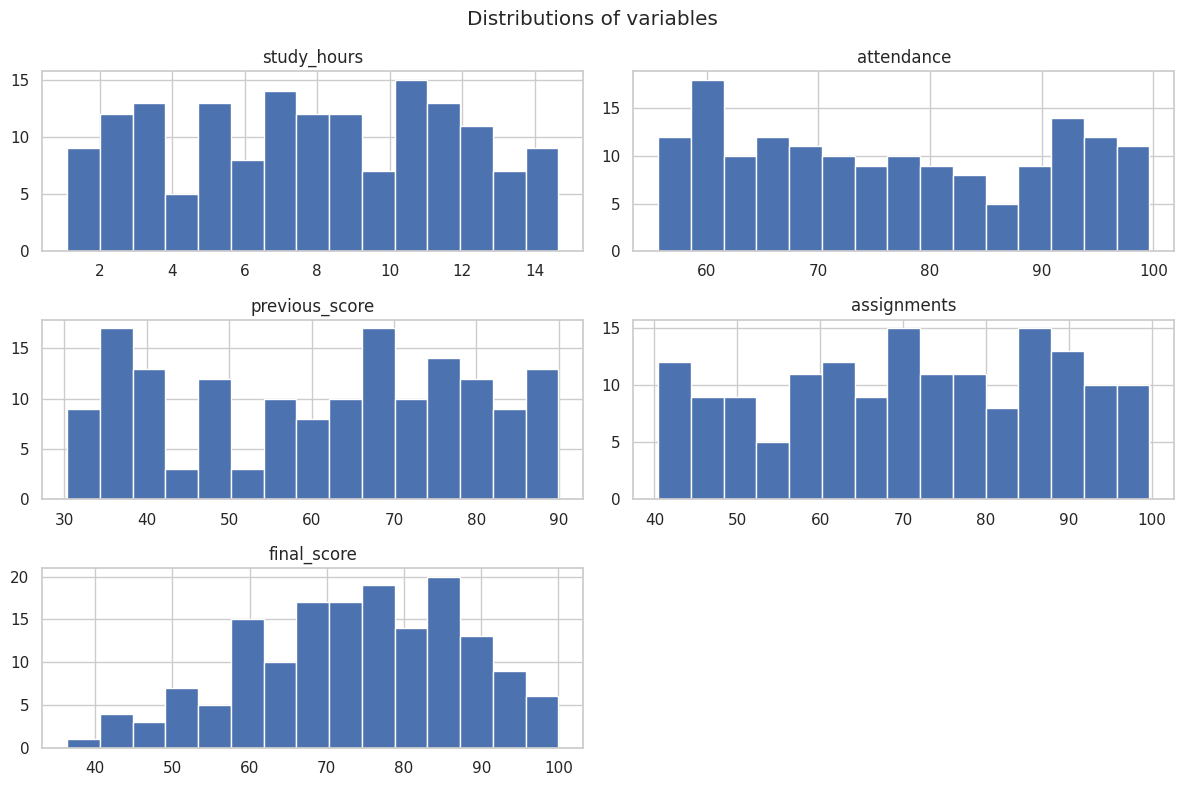

In [6]:
df.hist(figsize=(12, 8), bins=15)
plt.suptitle("Distributions of variables")
plt.tight_layout()
plt.show()



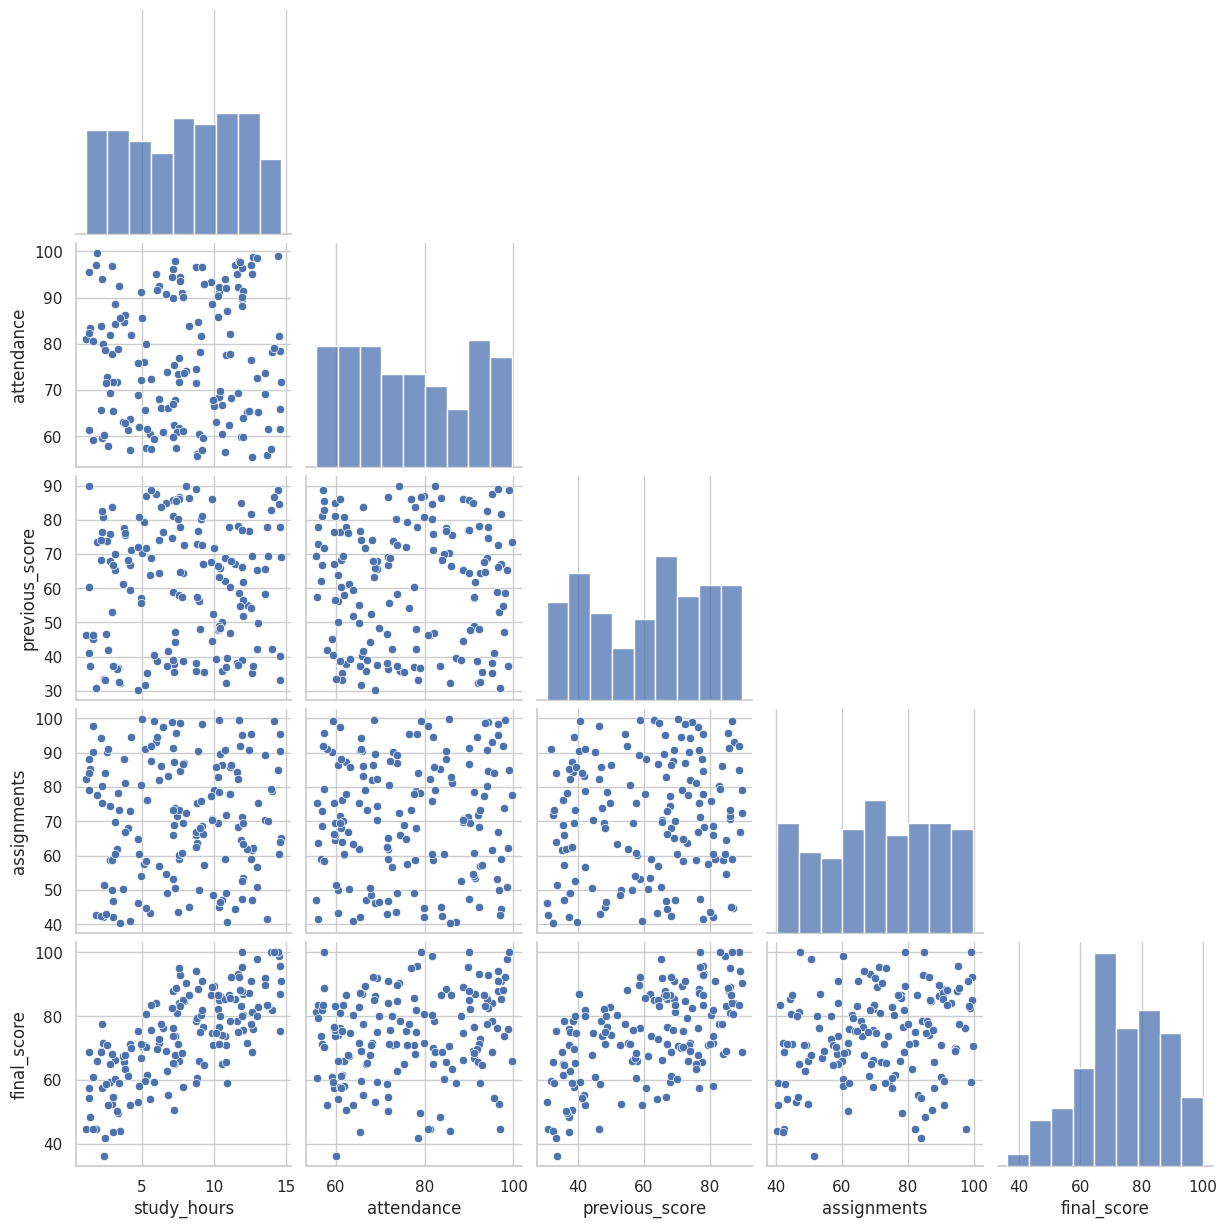

In [7]:
sns.pairplot(df, corner=True)
plt.show()



### Correlation interpretation
Pearson's r ranges from -1 to +1. Positive values indicate positive linear association; negative values indicate negative linear association; values near zero indicate weak linear association (but may hide nonlinear patterns). Correlation is not a regression coefficient: it does not control for other predictors.

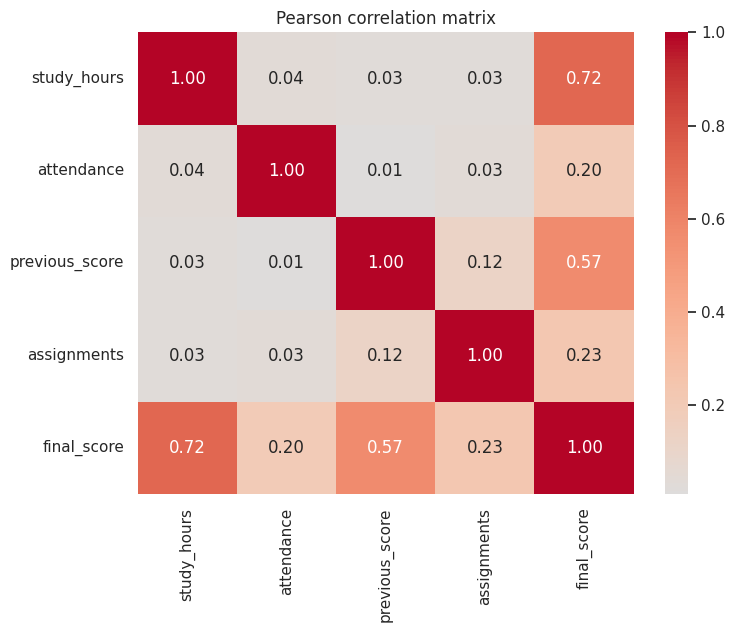

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Pearson correlation matrix")
plt.show()

## 4. Simple regression: calculate the equation by hand

Example data:

| Study hours X | Exam score Y |
|---:|---:|
| 1 | 35 |
| 2 | 40 |
| 3 | 50 |
| 4 | 55 |
| 5 | 65 |
| 6 | 70 |
| 7 | 80 |

\[
b_1=\frac{n\sum XY-\sum X\sum Y}{n\sum X^2-(\sum X)^2},
\qquad b_0=\bar Y-b_1\bar X
\]

The slope is the fitted score change per additional study hour; the intercept is the fitted score at zero hours.

In [9]:
simple = pd.DataFrame({
    "study_hours": [1,2,3,4,5,6,7],
    "exam_score": [35,40,50,55,65,70,80]
})


In [10]:
simple

,study_hours,exam_score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65
5,6,70
6,7,80


In [11]:
x = simple.study_hours.to_numpy()


In [12]:
x

array([1, 2, 3, 4, 5, 6, 7])

In [13]:
y = simple.exam_score.to_numpy()


In [14]:
y

array([35, 40, 50, 55, 65, 70, 80])

In [15]:
n0 = len(x)


In [16]:
n0

7

In [17]:
manual = pd.Series({
    "n": n0, "sum X": x.sum(), "sum Y": y.sum(),
    "sum X squared": (x**2).sum(), "sum XY": (x*y).sum(),
    "mean X": x.mean(), "mean Y": y.mean()
})
display(manual.to_frame("Value"))



,Value
n,7.000
sum X,28.000
sum Y,395.000
sum X squared,140.000
sum XY,"1,790.000"
mean X,4.000
mean Y,56.429


In [18]:
b1 = (n0*np.sum(x*y)-np.sum(x)*np.sum(y))/(n0*np.sum(x*x)-np.sum(x)**2)
b0 = y.mean()-b1*x.mean()
print(f"b1 = {b1:.4f}; b0 = {b0:.4f}")
print(f"Regression equation: predicted score = {b0:.2f} + {b1:.2f} × study hours")



b1 = 7.5000; b0 = 26.4286
Regression equation: predicted score = 26.43 + 7.50 × study hours


In [19]:
simple["predicted"] = b0+b1*x
simple["residual"] = y-simple.predicted
simple["squared_residual"] = simple.residual**2
display(simple)
print("SSE =", simple.squared_residual.sum())



,study_hours,exam_score,predicted,residual,squared_residual
0,1,35,33.929,1.071,1.148
1,2,40,41.429,-1.429,2.041
2,3,50,48.929,1.071,1.148
3,4,55,56.429,-1.429,2.041
4,5,65,63.929,1.071,1.148
5,6,70,71.429,-1.429,2.041
6,7,80,78.929,1.071,1.148


SSE = 10.714285714285715


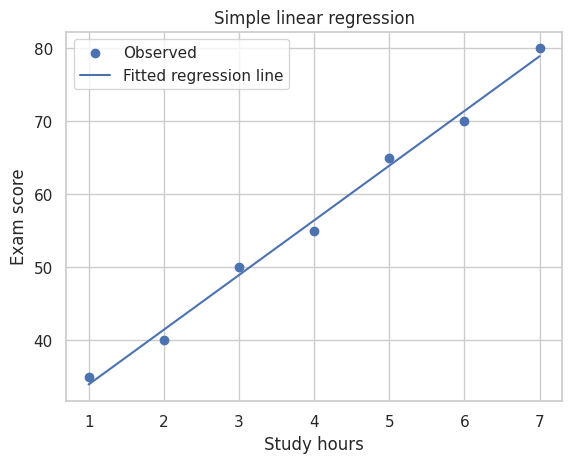

In [20]:
plt.scatter(x, y, label="Observed")
plt.plot(x, simple.predicted, label="Fitted regression line")
plt.xlabel("Study hours"); plt.ylabel("Exam score")
plt.legend(); plt.title("Simple linear regression")
plt.show()

### Interpret the worked equation
The estimated slope is 7.5: within this example, one additional study hour is associated with a 7.5-point increase in predicted score. The intercept is approximately 26.43: predicted score at zero study hours. Since zero is outside the observed range (1–7), its practical meaning is limited. The slope is an average fitted association, not a guaranteed individual gain.

## 5. Split data and fit multiple linear regression

We hold out 25% of the data for testing. The test set estimates performance on unseen observations. Do not repeatedly tune the model using the test set.

In [21]:
features = ["study_hours", "attendance", "previous_score", "assignments"]
target = "final_score"
X, y = df[features], df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
display(pd.Series(model.coef_, index=features, name="Coefficient").to_frame())

Intercept: 7.115167950487901


,Coefficient
study_hours,2.474
attendance,0.172
previous_score,0.409
assignments,0.130


## 6. Interpret the fitted coefficients

The equation is:

\[
\widehat{FinalScore}=b_0+b_1(StudyHours)+b_2(Attendance)+b_3(PreviousScore)+b_4(Assignments)
\]

For every coefficient, interpret:
1. **Sign:** positive or negative relationship.
2. **Magnitude:** expected target-unit change for a one-unit predictor change.
3. **Units:** e.g. score points per additional study hour.
4. **Holding constant:** other included predictors remain fixed.
5. **Uncertainty:** examine standard error and confidence interval.
6. **Practical significance:** is the size meaningful in the real context?
7. **Causal caution:** do not say “causes” unless the study design supports causal inference.

The intercept is the prediction when every predictor is zero. If zero is impossible or outside the data range, it may have little substantive meaning. If a percentage is stored 0–100, a one-unit change means one percentage point; if stored 0–1, the scale differs.

In [22]:
coef_interpretation = pd.DataFrame({
    "Predictor": features,
    "Coefficient": model.coef_,
    "Unit of predictor": [
        "one additional study hour",
        "one attendance percentage point",
        "one previous-score point",
        "one assignment-completion percentage point"
    ],
    "Interpretation template": [
        "Predicted score change per additional study hour, holding others fixed",
        "Predicted score change per attendance percentage point, holding others fixed",
        "Predicted score change per previous-score point, holding others fixed",
        "Predicted score change per assignment percentage point, holding others fixed"
    ]
})
display(coef_interpretation)

,Predictor,Coefficient,Unit of predictor,Interpretation template
0,study_hours,2.474,one additional study hour,Predicted score change per additional study ho...
1,attendance,0.172,one attendance percentage point,Predicted score change per attendance percenta...
2,previous_score,0.409,one previous-score point,Predicted score change per previous-score poin...
3,assignments,0.130,one assignment-completion percentage point,Predicted score change per assignment percenta...


## 7. Prediction and residual interpretation

\[
Residual_i = Actual_i - Predicted_i
\]

- Positive residual: actual is greater than predicted; model underpredicted.
- Negative residual: actual is less than predicted; model overpredicted.
- Residual near zero: prediction is close for that observation.

Residuals are sample-based estimates of unobserved errors.

In [23]:
y_pred = model.predict(X_test)
results = X_test.copy()
results["actual"] = y_test
results["predicted"] = y_pred
results["residual"] = results.actual-results.predicted
results["absolute_error"] = results.residual.abs()
display(results.head(12))

,study_hours,attendance,previous_score,assignments,actual,predicted,residual,absolute_error
105,11.036,62.449,78.089,77.850,86.470,87.211,-0.741,0.741
108,2.349,60.197,33.434,51.496,36.345,43.654,-7.309,7.309
141,7.870,61.055,38.708,69.382,57.882,61.935,-4.053,4.053
55,11.930,88.254,38.867,52.543,79.903,74.547,5.356,5.356
94,5.221,65.650,31.740,91.121,59.625,56.145,3.480,3.480
29,10.563,66.811,35.703,46.951,65.004,65.449,-0.446,0.446
101,10.796,92.110,32.170,71.885,65.682,72.176,-6.494,6.494
51,1.103,81.150,46.232,82.324,44.844,53.415,-8.571,8.571
100,13.720,61.578,69.376,69.929,83.431,89.109,-5.678,5.678
142,14.130,79.123,86.761,99.132,100.000,104.044,-4.044,4.044


## 8. Regression performance metrics

**MAE**: average absolute prediction error; target units; comparatively less sensitive to large errors.

\[
MAE=\frac{1}{n}\sum |y_i-\hat y_i|
\]

**MSE**: average squared error; large errors receive greater penalty; squared target units.

\[
MSE=\frac{1}{n}\sum (y_i-\hat y_i)^2
\]

**RMSE**: square root of MSE; target units; more sensitive to large errors than MAE.

\[
RMSE=\sqrt{MSE}
\]

**R-squared**: proportion of in-sample target variation explained relative to a mean-only model (for OLS with intercept). Test R² can be negative.

\[
R^2=1-\frac{SS_{res}}{SS_{tot}}
\]

**Adjusted R²**: adjusts R² for sample size and number of predictors; useful for comparing OLS models on the same response/sample, not a replacement for test performance.

\[
Adj.R^2=1-(1-R^2)\frac{n-1}{n-p-1}
\]

**MAPE**: average absolute percentage error. Avoid when actual values are zero or close to zero.

In [24]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2_test = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test-y_pred)/y_test))*100

metric_table = pd.Series({
    "MAE": mae, "MSE": mse, "RMSE": rmse,
    "Test R-squared": r2_test, "MAPE (%)": mape,
    "Training R-squared": model.score(X_train, y_train)
})
display(metric_table.to_frame("Value"))

baseline = np.repeat(y_train.mean(), len(y_test))
print("Baseline MAE:", mean_absolute_error(y_test, baseline))
print("Model MAE:", mae)
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, baseline)))
print("Model RMSE:", rmse)

,Value
MAE,4.571
MSE,30.618
RMSE,5.533
Test R-squared,0.877
MAPE (%),6.925
Training R-squared,0.852


Baseline MAE: 13.118264289497597
Model MAE: 4.5707154779983945
Baseline RMSE: 15.803747513094292
Model RMSE: 5.533317381857191


### Metric interpretation
Lower MAE/MSE/RMSE is better, but compare errors with the target's scale. Higher R² is generally better, but do not select a model using R² alone. A gap between training and test scores may indicate overfitting, distribution shift or an unlucky split. Compare with a baseline. MAPE is unstable around zero.

## 9. OLS statistical summary using statsmodels

Scikit-learn focuses on prediction. Statsmodels provides statistical inference: coefficient estimates, standard errors, t-statistics, p-values, confidence intervals, F-statistic, R², adjusted R², AIC and BIC.

In [25]:
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:            final_score   R-squared:                       0.852
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                     165.9
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           8.69e-47
Time:                        05:12:28   Log-Likelihood:                -366.11
No. Observations:                 120   AIC:                             742.2
Df Residuals:                     115   BIC:                             756.2
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.1152      3.738      1.

## 10. Interpret every important OLS output

| Field | What it means | How to interpret |
|---|---|---|
| `coef` | coefficient estimate | Expected target change per one-unit predictor increase, holding other predictors fixed |
| `const` | intercept | Predicted target when all predictors are zero |
| `std err` | standard error | Estimated sampling uncertainty of coefficient |
| `t` | t-statistic | Coefficient divided by standard error |
| `P>|t|` | p-value | Evidence against null that coefficient equals zero, conditional on model assumptions |
| `[0.025, 0.975]` | 95% CI | Plausible range for coefficient under the model and procedure |
| `R-squared` | fit measure | Fraction of in-sample target variation explained |
| `Adj. R-squared` | adjusted fit | Penalises unnecessary predictors |
| `F-statistic` | overall model test | Tests whether all slope coefficients are jointly zero |
| `Prob (F-statistic)` | overall p-value | Evidence that at least one slope is non-zero |
| `AIC` | information criterion | Relative fit/complexity score; lower preferred among comparable models |
| `BIC` | information criterion | Like AIC, generally penalises complexity more |
| `No. Observations` | sample size | Rows used in estimation |
| `Df Model` | model degrees of freedom | Number of slope parameters (rank-based) |
| `Df Residuals` | residual degrees of freedom | Observations less estimated parameters |
| `Covariance Type` | standard-error method | E.g. nonrobust or heteroskedasticity-robust |

**P-value caution:** p < .05 is a common significance convention, not proof of a large effect, causality, or correct assumptions. It is not the probability that the null hypothesis is true. A confidence interval containing zero corresponds to a non-significant two-sided test at the matching level.

In [26]:
ci = ols.conf_int()
inference = pd.DataFrame({
    "Coefficient": ols.params,
    "Std error": ols.bse,
    "t statistic": ols.tvalues,
    "p value": ols.pvalues,
    "CI lower 95%": ci[0],
    "CI upper 95%": ci[1]
})
inference["Significant at 5%"] = inference["p value"] < .05
display(inference)

,Coefficient,Std error,t statistic,p value,CI lower 95%,CI upper 95%,Significant at 5%
const,7.115,3.738,1.903,0.060,-0.290,14.520,False
study_hours,2.474,0.130,19.093,0.000,2.217,2.730,True
attendance,0.172,0.036,4.751,0.000,0.100,0.244,True
previous_score,0.409,0.028,14.589,0.000,0.353,0.464,True
assignments,0.130,0.027,4.793,0.000,0.076,0.183,True


## 11. Individual t-tests and overall F-test

For predictor j:

\[
H_0:\beta_j=0 \quad vs. \quad H_1:\beta_j\ne0
\]

The t-test evaluates an individual coefficient conditional on other predictors.

The overall F-test evaluates:

\[
H_0:\beta_1=\beta_2=\cdots=\beta_p=0
\]

A significant F-test means at least one slope contributes evidence of a relationship; it does not mean every predictor is individually significant.

In [27]:
print("F-statistic:", ols.fvalue)
print("Overall F-test p-value:", ols.f_pvalue)
print("Joint test for study_hours and attendance:")
print(ols.f_test("study_hours = 0, attendance = 0"))

F-statistic: 165.8960300615537
Overall F-test p-value: 8.691367988355922e-47
Joint test for study_hours and attendance:
<F test: F=195.00763211628148, p=1.1223202093050433e-37, df_denom=115, df_num=2>


## 12. Confidence interval vs prediction interval

A **confidence interval** estimates uncertainty around the mean response for given inputs. A **prediction interval** estimates a range for one new observation and is wider because it includes individual-level noise. Neither is a guarantee.

In [28]:
prediction_frame = ols.get_prediction(
    sm.add_constant(X_test, has_constant="add")
).summary_frame(alpha=.05)
display(prediction_frame.head())

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
105,87.211,0.980,85.271,89.152,76.683,97.739
108,43.654,1.341,40.998,46.310,32.971,54.337
141,61.935,1.008,59.939,63.931,51.397,72.473
55,74.547,1.156,72.257,76.837,63.949,85.145
94,56.145,1.296,53.579,58.712,45.484,66.807


## 13. Assumptions and residual diagnostics

Key classical OLS assumptions and issues:
1. **Correct functional form / linearity in parameters:** the conditional mean is adequately represented.
2. **Zero conditional mean / exogeneity:** errors have mean zero conditional on predictors; violation can bias coefficients.
3. **Independence:** errors are not dependent; important for time series, repeated measures and clusters.
4. **Homoskedasticity:** error variance is constant; heteroskedasticity can invalidate conventional standard errors.
5. **No perfect multicollinearity:** no predictor is an exact linear combination of others.
6. **Normality of errors:** mainly supports exact small-sample classical inference; not needed to calculate OLS coefficients.
7. **No highly influential data errors:** unusual observations may strongly affect the fit.

Residual plots are clues, not automatic pass/fail tests.

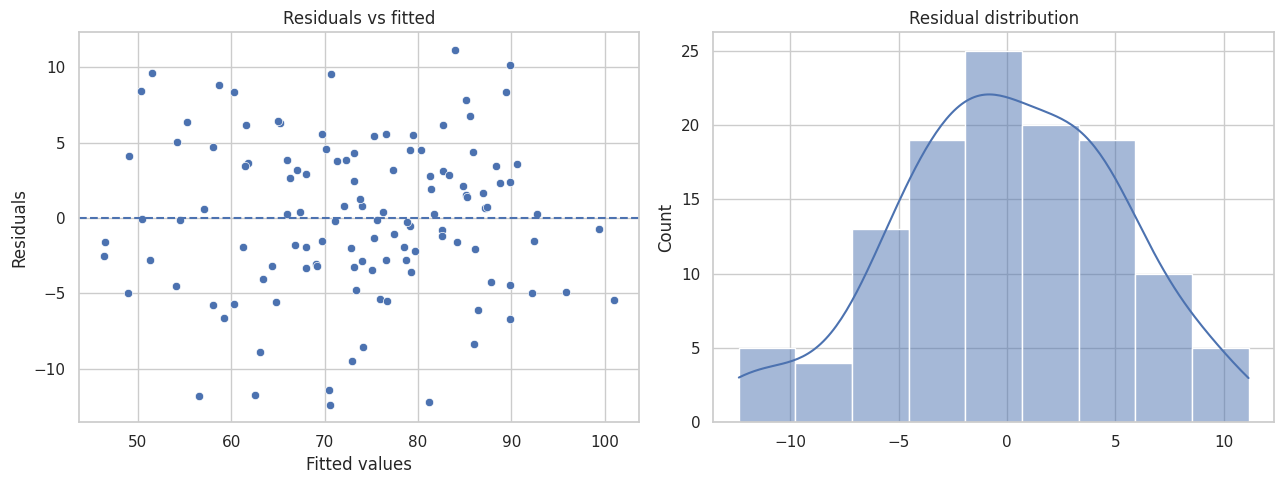

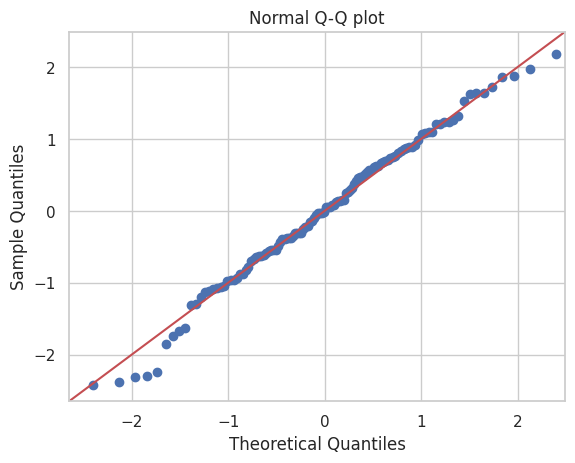

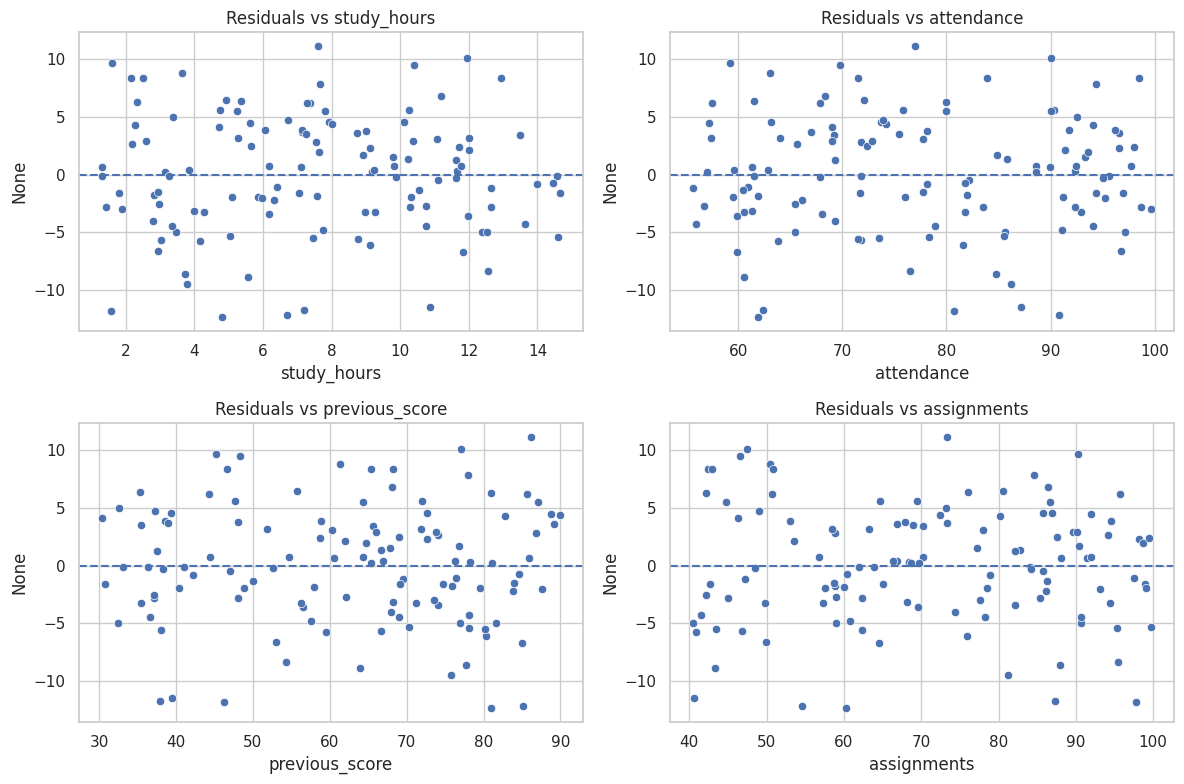

In [29]:
fitted = ols.fittedvalues
resid = ols.resid

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=fitted, y=resid, ax=axes[0])
axes[0].axhline(0, ls="--")
axes[0].set(title="Residuals vs fitted", xlabel="Fitted values", ylabel="Residuals")
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

sm.qqplot(resid, line="45", fit=True)
plt.title("Normal Q-Q plot"); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, features):
    sns.scatterplot(x=X_train[col], y=resid, ax=ax)
    ax.axhline(0, ls="--")
    ax.set_title(f"Residuals vs {col}")
plt.tight_layout(); plt.show()

### How to read diagnostic plots
- Random horizontal cloud around zero: broadly reassuring.
- Curved pattern: possible nonlinearity or omitted structure.
- Funnel/widening spread: possible heteroskedasticity.
- Clusters or waves: possible group effects or dependence.
- Q-Q departures: residual distribution differs from normality.
Normality is most relevant to small-sample classical inference; it is not required to compute OLS coefficients.

## 14. Heteroskedasticity: Breusch–Pagan and robust standard errors

Breusch–Pagan null hypothesis: constant error variance. A small p-value is evidence against homoskedasticity. HC robust standard errors can make inference more robust to heteroskedasticity; they do not fix omitted-variable bias, endogeneity or incorrect functional form.

In [30]:
bp = het_breuschpagan(resid, X_train_sm)
print(dict(zip(
    ["LM statistic", "LM p-value", "F statistic", "F p-value"], bp
)))
robust_ols = ols.get_robustcov_results(cov_type="HC3")
print(robust_ols.summary())

{'LM statistic': np.float64(5.384365718532118), 'LM p-value': np.float64(0.2500823500050376), 'F statistic': np.float64(1.3506055729504245), 'F p-value': np.float64(0.2555550639838179)}
                            OLS Regression Results                            
Dep. Variable:            final_score   R-squared:                       0.852
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                     156.3
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.59e-45
Time:                        05:12:31   Log-Likelihood:                -366.11
No. Observations:                 120   AIC:                             742.2
Df Residuals:                     115   BIC:                             756.2
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                     coe

## 15. Multicollinearity and VIF

Multicollinearity means predictors are linearly related. It can inflate standard errors, destabilise coefficients, produce unexpected signs and make individual effects difficult to separate. It does not necessarily harm predictive accuracy.

\[
VIF_j=\frac{1}{1-R_j^2}
\]

Here R² is obtained by regressing predictor j on all other predictors. VIF > 5 or > 10 are common screening heuristics, not universal laws.

In [31]:
vif_X = sm.add_constant(X_train)
vif = pd.DataFrame({
    "Feature": vif_X.columns,
    "VIF": [variance_inflation_factor(vif_X.values, i)
            for i in range(vif_X.shape[1])]
})
display(vif)

,Feature,VIF
0,const,1.000
1,study_hours,1.001
2,attendance,1.008
3,previous_score,1.015
4,assignments,1.023


## 16. Autocorrelation: Durbin–Watson

Autocorrelation is correlation between errors across an ordering, often time. Durbin–Watson is roughly between 0 and 4: around 2 suggests little first-order autocorrelation; below 2 suggests positive tendency; above 2 suggests negative tendency. It is not a universal test for every dependence structure. For unordered cross-sectional data, it may not be meaningful.

In [32]:
print("Durbin-Watson:", durbin_watson(resid))

Durbin-Watson: 1.9502805867714625


## 17. Outliers, leverage and influence

- **Y-outlier:** unusual response relative to the fitted model.
- **High leverage:** unusual predictor combination.
- **Influential observation:** materially changes the fitted model.
- **Cook's distance:** combines residual size and leverage to screen influence.

A common screening threshold is 4/n, but it is only a heuristic. Never delete a row automatically: check data entry and context.

,dfb_const,dfb_study_hours,dfb_attendance,dfb_previous_score,dfb_assignments,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
26,0.005,0.000,-0.017,0.077,-0.041,0.002,0.545,0.033,0.100,0.543,0.100
138,-0.131,0.229,0.204,0.198,-0.292,0.045,1.992,0.054,0.476,2.018,0.482
82,0.030,-0.119,0.092,-0.064,-0.098,0.009,-0.974,0.046,-0.213,-0.974,-0.213
96,-0.036,-0.029,0.067,-0.106,0.100,0.006,0.752,0.052,0.175,0.751,0.175
146,-0.001,-0.023,-0.020,0.013,0.042,0.001,0.480,0.021,0.070,0.478,0.069


4/n screening threshold: 0.03333333333333333
Observations above threshold: 8


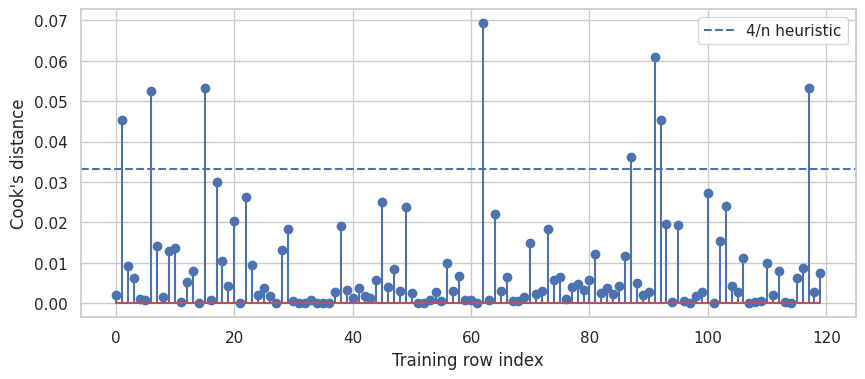

In [33]:
infl = ols.get_influence()
infl_df = infl.summary_frame()
display(infl_df.head())
cook = infl_df["cooks_d"]
threshold = 4/len(X_train)
print("4/n screening threshold:", threshold)
print("Observations above threshold:", (cook > threshold).sum())

plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(cook)), cook)
plt.axhline(threshold, ls="--", label="4/n heuristic")
plt.xlabel("Training row index"); plt.ylabel("Cook's distance")
plt.legend(); plt.show()

## 18. Functional form, transformations and interactions

Regression is linear in coefficients, but predictors can be transformed:
- Quadratic: \(Y=b_0+b_1X+b_2X^2+e\). Marginal slope is \(b_1+2b_2X\).
- Log outcome: \(\log(Y)=b_0+b_1X+e\). Approximate percentage change is 100b₁%; exact is \(100(e^{b_1}-1)\%\).
- Interaction: \(Y=b_0+b_1X_1+b_2X_2+b_3X_1X_2+e\). The effect of X₁ depends on X₂.

Always interpret transformed terms together; do not interpret b₁ in a quadratic model as a constant slope.

In [34]:
quad = simple.copy()
quad["hours_sq"] = quad.study_hours**2
quad_fit = sm.OLS(
    quad.exam_score,
    sm.add_constant(quad[["study_hours", "hours_sq"]])
).fit()
print(quad_fit.summary())

b1q = quad_fit.params["study_hours"]
b2q = quad_fit.params["hours_sq"]
for h in [2, 4, 6]:
    print(f"Marginal score change at {h} hours:",
          b1q + 2*b2q*h)

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.991
Method:                 Least Squares   F-statistic:                     331.0
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           3.61e-05
Time:                        05:12:32   Log-Likelihood:                -11.010
No. Observations:                   7   AIC:                             28.02
Df Residuals:                       4   BIC:                             27.86
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          27.8571      2.405     11.585      

/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


## 19. Categorical predictors and dummy variables

For a categorical predictor with g categories, use g−1 dummy variables when the model includes an intercept. The omitted category is the **reference category**. Each dummy coefficient is the estimated difference from the reference category, holding other predictors constant. Including all g dummies plus an intercept creates perfect multicollinearity (dummy-variable trap).

In [35]:
cat_df = df.copy()
rng_cat = np.random.default_rng(7)
cat_df["programme"] = rng_cat.choice(["A", "B", "C"], len(cat_df))
cat_df["score_adjusted"] = cat_df.final_score + cat_df.programme.map(
    {"A": 0, "B": 2, "C": -1}
)
cat_df = pd.get_dummies(cat_df, columns=["programme"], drop_first=True, dtype=int)
cat_features = features + ["programme_B", "programme_C"]
cat_ols = sm.OLS(
    cat_df.score_adjusted,
    sm.add_constant(cat_df[cat_features])
).fit()
print(cat_ols.summary())

                            OLS Regression Results                            
Dep. Variable:         score_adjusted   R-squared:                       0.857
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                     152.4
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           6.48e-62
Time:                        05:12:32   Log-Likelihood:                -490.52
No. Observations:                 160   AIC:                             995.0
Df Residuals:                     153   BIC:                             1017.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.9342      3.540      2.

## 20. Standardised coefficients

Standardised coefficients express the expected change in target standard deviations for a one-standard-deviation increase in a predictor. They can aid comparison across different units, but correlated predictors complicate interpretation. Raw coefficients are usually more useful for practical business interpretation.

In [36]:
Xstd = (X_train-X_train.mean())/X_train.std(ddof=0)
ystd = (y_train-y_train.mean())/y_train.std(ddof=0)
std_fit = LinearRegression().fit(Xstd, ystd)
display(pd.Series(std_fit.coef_, index=features,
                  name="Standardised coefficient").to_frame())

,Standardised coefficient
study_hours,0.685
attendance,0.171
previous_score,0.527
assignments,0.174


## 21. Cross-validation and regularisation

K-fold cross-validation repeatedly fits on subsets of training data and evaluates held-out folds. Use time-aware splits for time series and group-aware splits for repeated observations from the same person/customer.

**Ridge (L2):** penalises squared coefficients; shrinks them toward zero.  
**Lasso (L1):** penalises absolute coefficients; may set some coefficients exactly to zero.  
Scale features before regularisation. Choose alpha using cross-validation, not the test set.

In [37]:
cv_rmse = -cross_val_score(
    LinearRegression(), X_train, y_train,
    cv=5, scoring="neg_root_mean_squared_error"
)
print("CV RMSE by fold:", np.round(cv_rmse, 3))
print("Mean CV RMSE:", cv_rmse.mean(), "SD:", cv_rmse.std())

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
lasso = make_pipeline(StandardScaler(), Lasso(alpha=.1, max_iter=10000))
for name, estimator in [("Ridge", ridge), ("Lasso", lasso)]:
    estimator.fit(X_train, y_train)
    p = estimator.predict(X_test)
    print(name, "MAE", mean_absolute_error(y_test, p),
          "RMSE", np.sqrt(mean_squared_error(y_test, p)),
          "R2", r2_score(y_test, p))

CV RMSE by fold: [5.884 4.152 5.061 6.26  5.19 ]
Mean CV RMSE: 5.309477104347037 SD: 0.7282693267205196
Ridge MAE 4.587733261618706 RMSE 5.545941271617385 R2 0.8766153919594909
Lasso MAE 4.585486081204742 RMSE 5.543278241619112 R2 0.876733856259422


## 22. Predict a new observation and check extrapolation

Supply the same variables, units and preprocessing used at training. Predictions outside the training range are extrapolations and may be unreliable.

In [38]:
new_student = pd.DataFrame({
    "study_hours": [8],
    "attendance": [90],
    "previous_score": [72],
    "assignments": [85]
})
print("Predicted final score:", model.predict(new_student)[0])
display(pd.DataFrame({
    "training_min": X_train.min(),
    "new_value": new_student.iloc[0],
    "training_max": X_train.max()
}))

Predicted final score: 82.88540656117009


,training_min,new_value,training_max
study_hours,1.303,8,14.659
attendance,55.627,90,99.657
previous_score,30.326,72,89.946
assignments,40.439,85,99.728


## 23. Common interpretation mistakes
1. Treating association as causation.
2. Omitting predictor and target units.
3. Forgetting “holding other variables constant.”
4. Comparing raw coefficients across different scales.
5. Using R² alone to judge a model.
6. Treating p < .05 as proof of practical importance.
7. Automatically deleting outliers.
8. Ignoring multicollinearity and coefficient instability.
9. Using MAPE with zero or near-zero actual values.
10. Extrapolating beyond observed data.
11. Data leakage: using future/unavailable information or fitting preprocessing on all data before splitting.
12. Ignoring dependence in time-series, repeated-measure or grouped data.

## 24. Model reporting template

**Objective:** state the target and purpose.  
**Data:** sample size, period, predictors, missing-data treatment, split strategy.  
**Equation:** write the fitted equation with units.  
**Coefficients:** sign, magnitude, units, holding-constant condition, CI, p-value, practical relevance.  
**Overall fit:** R², adjusted R², F-statistic and p-value.  
**Prediction quality:** test MAE, RMSE, R² and baseline comparison.  
**Diagnostics:** residual patterns, heteroskedasticity, VIF, autocorrelation where relevant, influential cases.  
**Limitations:** confounding, omitted variables, sample representativeness, measurement error, extrapolation.  
**Conclusion:** state what the evidence supports and what it does not.

## 25. Classroom exercise with answer guide

A retailer predicts monthly sales (₹ lakh) using advertising spend (₹ lakh), footfall (thousand visitors), and discount rate (percentage points).

1. Interpret advertising coefficient = 1.8.
2. Interpret footfall coefficient = 0.45.
3. Interpret discount coefficient = 0.7.
4. Interpret intercept = 12. When might it be meaningless?
5. Explain R² = 0.82.
6. What might a fall in adjusted R² after adding a predictor suggest?
7. Advertising p-value = 0.03 and 95% CI = [0.2, 3.4]. What can be concluded?
8. What should be investigated if advertising VIF = 8.5?
9. Explain RMSE = ₹4.2 lakh to a manager.
10. Why does statistical significance not prove advertising caused higher sales?

### Suggested answers
1. Holding other variables constant, ₹1 lakh additional advertising spend is associated with ₹1.8 lakh higher predicted monthly sales.
2. One additional thousand visitors is associated with ₹0.45 lakh higher predicted sales, holding other variables fixed.
3. One percentage-point increase in discount rate is associated with ₹0.7 lakh higher predicted sales, holding others fixed (assuming percentage-point coding).
4. Predicted sales when all predictors are zero; may be outside observed data and not meaningful.
5. The model explains 82% of in-sample variation in sales under the usual OLS-with-intercept definition.
6. The new predictor may not improve fit enough to justify complexity.
7. Positive coefficient evidence at 5% under model assumptions; CI excludes zero. Not proof of causation or practical importance.
8. Relationships among predictors, coefficient stability, standard errors and overlapping business effects.
9. RMSE indicates a typical squared-error-weighted prediction deviation around ₹4.2 lakh; it is not a guarantee every prediction is within that amount.
10. Confounding, reverse causality, omitted variables and non-random advertising allocation may explain the association.

## 26. Final interpretation checklist

- [ ] Target and predictors clearly identified.
- [ ] Units and coding explained.
- [ ] Fitted equation reported.
- [ ] Intercept interpreted with context.
- [ ] Every coefficient interpreted holding other predictors constant.
- [ ] Standard errors, p-values and confidence intervals considered.
- [ ] Overall F-test explained.
- [ ] R² and adjusted R² interpreted without overclaiming.
- [ ] Test MAE/RMSE and baseline comparison reported.
- [ ] Residual diagnostics examined.
- [ ] VIF and influential observations reviewed.
- [ ] Validation split matches time/group structure.
- [ ] Practical importance and causal limitations stated.

**Takeaway:** A strong regression analysis is more than a high R². It combines good data preparation, interpretable coefficients, uncertainty, out-of-sample evaluation, diagnostics and careful communication.